<a href="https://colab.research.google.com/github/jhlopesalves/eda_humanidades/blob/main/encontro_10/enc_10-parte2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Google Colab"/></a>

<p class="lesson-runtime-note">No site, as saídas são resultados salvos. Para executar o código, abra o notebook no Colab.</p>

# Encontro 10, parte 2: Bootstrap, erro padrão e intervalos de confiança

Na [primeira parte](enc_10.ipynb), estudamos a incerteza da proporção de VPO.
A simulação partia de um modelo ajustado; o bootstrap partia dos valores
observados. Agora aprofundaremos a segunda rota com dados de **decisão lexical**,
em que cada resposta pertence a um participante e a uma palavra.

Partimos da situação usual da pesquisa: temos uma amostra e queremos estimar
uma quantidade de interesse e sua incerteza. O parâmetro populacional permanece
desconhecido. A interpretação do resultado depende da pergunta, do desenho
da coleta e da unidade que reamostramos.

Primeiro construiremos resumos por participante e estudaremos sua média e
mediana. Depois, construiremos resumos por palavra para examinar a associação
entre frequência lexical e tempo de reação. Ao retornar aos ensaios,
compararemos três esquemas de reamostragem para **a mesma estatística**.
A implementação manual precederá a função do SciPy.

## 1. Preparação e sequência aleatória

As importações e o gerador ficam no começo para que todas as células
dependam do mesmo estado de execução. `np` é o nome abreviado de NumPy
usado nos encontros anteriores.

In [1]:
#| code-fold: true
#| code-summary: "Mostrar importações"
#| warning: false

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns
from IPython.display import Markdown, display

In [2]:
#| label: inicializar-gerador

rng = np.random.default_rng(seed=42)

A semente 42 reproduz a sequência quando executamos o notebook
inteiro, na mesma ordem e no mesmo ambiente. Cada sorteio avança o estado
de `rng`; repetir uma célula isolada produz outros valores e também muda
os sorteios posteriores. Para reproduzir as saídas salvas, reinicie a
sessão e execute desde o começo. Não reinicializaremos o gerador entre análises.

A leitura procura primeiro `data/lexdec.csv`, para execução na pasta
do encontro, e depois `encontro_10/data/lexdec.csv`, para execução na raiz
do repositório. Se nenhuma cópia estiver disponível, usa a URL fixa.

In [3]:
#| code-fold: true
#| code-summary: "Mostrar leitura do LexDec"

lexdec_url = (
    "https://raw.githubusercontent.com/jhlopesalves/eda_humanidades/"
    "0c047c1d3b1fe9b7a5f9ea3677a4ecc618336bf6/"
    "encontro_10/data/lexdec.csv"
)

lexdec_path = Path("data/lexdec.csv")
if not lexdec_path.exists():
    lexdec_path = Path("encontro_10/data/lexdec.csv")

lexdec_source = lexdec_url
if lexdec_path.exists():
    lexdec_source = lexdec_path

lexdec_df = pd.read_csv(lexdec_source)

## 2. Dados e desenho do experimento

Em uma tarefa de **decisão lexical**, o participante decide se a sequência
apresentada é uma palavra. O LexDec registra respostas de 21 participantes a
79 substantivos concretos do inglês, totalizando 1.659 ensaios. `Correct`
indica se o item foi corretamente identificado como palavra.

O conjunto `lexdec` integra o pacote R `languageR`. A
[documentação do conjunto](https://cran.r-project.org/web/packages/languageR/languageR.pdf#page=54)
informa o desenho, as variáveis e a coleta com Jen Hay, na University of
Canterbury, em 2004. Esses dados documentam o conjunto de referência; o histórico
da aquisição e da exportação desta cópia local tem lacunas registradas em
[Dados e proveniência](../DATASETS.md).

Cada linha reúne o participante (`Subject`), a palavra (`Word`) e a resposta.
`RT` contém tempos de reação já transformados em logaritmos; `Frequency`
contém frequências de lema do CELEX também em logaritmos. Manteremos as
escalas fornecidas, sem aplicar uma segunda transformação.

Como cada participante responde a vários itens e cada item aparece para vários
participantes, temos **medidas repetidas em uma estrutura cruzada**. Antes da
análise, inspecionaremos as colunas e conferiremos essa estrutura.

In [4]:
#| label: lexdec-colunas
#| classes: ["output-scroll"]
#| code-fold: true
#| code-summary: "Mostrar estrutura dos dados"

lexdec_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1659 entries, 0 to 1658
Data columns (total 28 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Subject         1659 non-null   str    
 1   RT              1659 non-null   float64
 2   Trial           1659 non-null   int64  
 3   Sex             1659 non-null   str    
 4   NativeLanguage  1659 non-null   str    
 5   Correct         1659 non-null   str    
 6   PrevType        1659 non-null   str    
 7   PrevCorrect     1659 non-null   str    
 8   Word            1659 non-null   str    
 9   Frequency       1659 non-null   float64
 10  FamilySize      1659 non-null   float64
 11  SynsetCount     1659 non-null   float64
 12  Length          1659 non-null   int64  
 13  Class           1659 non-null   str    
 14  FreqSingular    1659 non-null   int64  
 15  FreqPlural      1659 non-null   int64  
 16  DerivEntropy    1659 non-null   float64
 17  Complex         1659 non-null   str    
 18 

A inspeção distingue identificadores, categorias e medições numéricas.
Os nomes originais misturam convenções de escrita. Usaremos o glossário
`lexdec_colunas.csv` para renomeá-los de forma consistente, sem alterar
os valores. O campo `nivel` indica se uma coluna descreve participante,
palavra ou tentativa.

In [5]:
#| code-fold: true
#| code-summary: "Mostrar leitura do glossário"

info_colunas_url = (
    "https://raw.githubusercontent.com/jhlopesalves/eda_humanidades/"
    "97b1ab8a1a1c2603a9f09b203aa46b66a4b9a89e/"
    "encontro_10/data/lexdec_colunas.csv"
)

info_colunas_path = Path("data/lexdec_colunas.csv")
if not info_colunas_path.exists():
    info_colunas_path = Path("encontro_10/data/lexdec_colunas.csv")

info_colunas_source = info_colunas_url
if info_colunas_path.exists():
    info_colunas_source = info_colunas_path

info_colunas = pd.read_csv(info_colunas_source)

In [6]:
#| label: lexdec-glossario
#| classes: ["output-scroll"]

print("Primeiras correspondências do glossário:")
for original, coluna in zip(
    info_colunas["original"].head(),
    info_colunas["coluna"].head(),
):
    print(f"{original}: {coluna}")

Primeiras correspondências do glossário:
Subject: subject
RT: rt_log
Trial: trial
Sex: sex
NativeLanguage: native_language


O dicionário associa cada nome original ao nome padronizado.
Verificamos correspondência completa e nomes únicos antes da conversão.
Depois usamos `coluna` como índice do glossário, para consultar uma
descrição com `.loc[]` ou um único valor com `.at[]`.

In [7]:
#| label: padronizar-colunas

if not info_colunas["original"].is_unique:
    raise ValueError("O glossário repete nomes originais.")
if not info_colunas["coluna"].is_unique:
    raise ValueError("O glossário repete nomes padronizados.")
if set(info_colunas["original"]) != set(lexdec_df.columns):
    raise ValueError("As colunas do LexDec e do glossário não correspondem.")

column_names = dict(zip(info_colunas["original"], info_colunas["coluna"]))
lexdec_df = lexdec_df.rename(columns=column_names)
glossario_colunas = info_colunas.set_index("coluna")

In [8]:
#| label: lexdec-niveis
#| classes: ["output-scroll"]

for coluna in ["rt_log", "item_mean_rt"]:
    print(f"{coluna}: {glossario_colunas.at[coluna, 'descricao']}")

rt_log: Tempo de reação do participante nesta tentativa, transformado em escala logarítmica.
item_mean_rt: Tempo de reação médio para essa palavra, calculado entre os participantes.


`rt_log` descreve um ensaio; `item_mean_rt` é um resumo por
palavra já presente no arquivo. Essa diferença de nível será importante
na agregação. O recorte aleatório seguinte mostra cinco ensaios com
as colunas que usaremos, passando `random_state=rng` ao pandas.

In [9]:
#| label: tbl-lexdec-recorte
#| tbl-cap: "Cinco ensaios da tabela, antes do filtro de acertos."
#| classes: ["table-responsive"]

lexdec_df[
    ["subject", "word", "rt_log", "correct", "frequency_log", "word_length"]
].sample(n=5, random_state=rng).round(4)

,subject,word,rt_log,correct,frequency_log,word_length
1281,T2,kiwi,6.5737,correct,3.0445,4
727,M2,wasp,7.0193,correct,4.6821,4
1084,R3,pineapple,6.3767,correct,3.9890,9
147,A2,squirrel,6.5221,correct,4.7095,8
718,M2,eggplant,6.7274,correct,1.7918,8


### 2.1 Linhas, participantes e palavras

Se cada participante respondeu uma vez a cada palavra, o desenho completo tem:

$$
21\text{ participantes}\times79\text{ palavras}
=1.659\text{ ensaios}.
$$

A contagem de linhas descreve ensaios; as contagens de participantes e
palavras descrevem dois conjuntos de unidades que se repetem nesses ensaios.
Conferiremos as respostas e as contagens por unidade antes de verificar
cada combinação participante–palavra.

As contagens de respostas separam acertos e erros. As contagens
por participante e por palavra ajudam a verificar o balanceamento antes
de aplicar o filtro de acertos.

In [10]:
#| label: lexdec-acertos
#| classes: ["output-scroll"]

response_counts = lexdec_df["correct"].value_counts()
print(f"Respostas corretas: {response_counts['correct']}")
print(f"Respostas incorretas: {response_counts['incorrect']}")

Respostas corretas: 1594
Respostas incorretas: 65


In [11]:
#| label: lexdec-contagens-participantes
#| classes: ["output-scroll"]

ensaios_por_participante = lexdec_df.groupby("subject").size()
print(f"Participantes: {len(ensaios_por_participante)}")
print(
    "Contagens de ensaios por participante: "
    + ", ".join(str(n) for n in ensaios_por_participante.unique())
)

Participantes: 21
Contagens de ensaios por participante: 79


In [12]:
#| label: lexdec-contagens-palavras
#| classes: ["output-scroll"]

ensaios_por_palavra = lexdec_df.groupby("word").size()
print(f"Palavras: {len(ensaios_por_palavra)}")
print(
    "Contagens de ensaios por palavra: "
    + ", ".join(str(n) for n in ensaios_por_palavra.unique())
)

Palavras: 79
Contagens de ensaios por palavra: 21


Cada participante tem 79 ensaios e cada palavra aparece 21 vezes.
Isso confirma contagens iguais por unidade, mas **não basta para verificar
todas as combinações**: uma combinação repetida poderia substituir outra
ausente sem alterar os totais. Conferiremos também se cada par
`subject`–`word` aparece exatamente uma vez e se existem $21\times79$ pares.

In [13]:
#| label: lexdec-desenho
#| classes: ["output-scroll"]

n_subjects_original = lexdec_df["subject"].nunique()
n_words_original = lexdec_df["word"].nunique()
pair_counts = lexdec_df.groupby(["subject", "word"]).size()

# Totais iguais por unidade não excluem pares repetidos ou ausentes.
if (
    len(pair_counts) != n_subjects_original * n_words_original
    or not pair_counts.eq(1).all()
):
    raise ValueError("O desenho não contém exatamente um ensaio por par.")

print(f"Participantes: {n_subjects_original}")
print(f"Palavras: {n_words_original}")
print(f"Pares distintos: {len(pair_counts)}")
print(f"Ensaios: {len(lexdec_df)}")

Participantes: 21
Palavras: 79
Pares distintos: 1659
Ensaios: 1659


A verificação confirma 21 participantes, 79 palavras e 1.659
pares distintos, cada um registrado uma vez. Há 1.594 respostas corretas
e 65 incorretas. O desenho original é completo; o filtro seguinte pode
deixar quantidades diferentes de ensaios nas unidades.

### 2.2 Ensaios corretos e escala de RT

Nossa análise tratará do tempo de uma **decisão lexical correta**. Selecionar
as respostas classificadas como `correct` define esse objeto de pesquisa;
analisar erros ou a probabilidade de acerto exigiria outra pergunta.

Antes de filtrar, verificamos valores ausentes nas colunas usadas, as duas
categorias de resposta e a presença de valores numéricos finitos. Não
substituiremos nem eliminaremos silenciosamente valores problemáticos.

::: {.callout-note title="A escala faz parte da estatística"}
Calcularemos médias e medianas **dos logaritmos registrados**. A média dos
logaritmos e o logaritmo de uma média na escala original são quantidades
distintas. Estimativas, desvios-padrão, erros padrão e intervalos de RT
permanecerão na escala fornecida; não os interpretaremos como milissegundos.
:::

O filtro retém 1.594 ensaios e pode alterar quantas respostas contribuem
para cada participante e cada palavra. Primeiro resumiremos os valores
retidos e examinaremos seu histograma.

In [14]:
#| label: lexdec-rt-corretos
#| classes: ["output-scroll"]

correct_df = lexdec_df.loc[lexdec_df["correct"] == "correct"].copy()

print(f"Ensaios corretos retidos: {len(correct_df)}")
print(
    "Média de RT nos ensaios corretos (log): "
    f"{correct_df['rt_log'].mean():.4f}"
)
print(
    "Mediana de RT nos ensaios corretos (log): "
    f"{correct_df['rt_log'].median():.4f}"
)

Ensaios corretos retidos: 1594
Média de RT nos ensaios corretos (log): 6.3839
Mediana de RT nos ensaios corretos (log): 6.3474


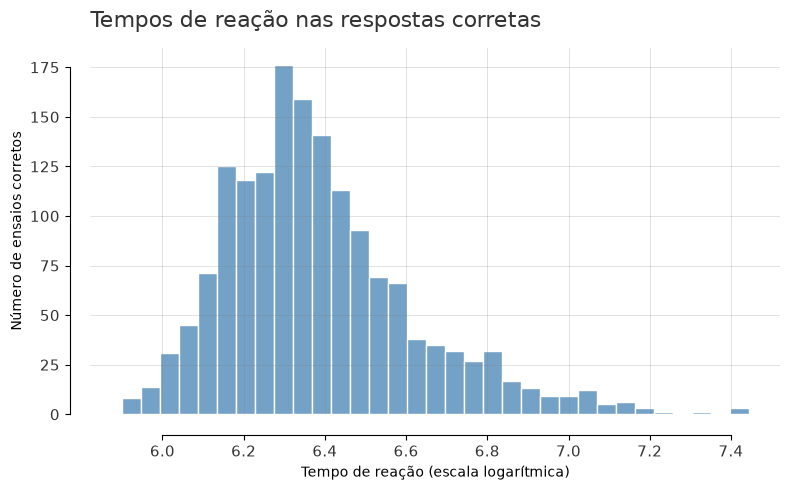

In [15]:
#| label: fig-lexdec-ensaios
#| fig-cap: "Distribuição dos tempos de reação nos 1.594 ensaios corretos, em logaritmos."
#| fig-alt: "Histograma de RT em log nos ensaios corretos, concentrado perto de 6,3 e com cauda mais longa à direita."
#| code-fold: true
#| code-summary: "Mostrar construção do gráfico"

fig, ax = plt.subplots(figsize=(8, 5))

sns.histplot(
    data=correct_df,
    x="rt_log",
    bins="fd",
    color="steelblue",
    edgecolor="white",
    ax=ax,
)

ax.set_title(
    "Tempos de reação nas respostas corretas",
    loc="left",
    fontsize=16,
    color="#333333",
    pad=15,
)
ax.set(
    xlabel="Tempo de reação (escala logarítmica)",
    ylabel="Número de ensaios corretos",
)

ax.tick_params(axis="both", labelsize=11, labelcolor="#333333")
ax.grid(axis="both", alpha=0.4, linewidth=0.4, color="grey")
sns.despine(ax=ax, top=True, left=False, trim=True, offset=15)
fig.tight_layout()
plt.show()

Na @fig-lexdec-ensaios, as respostas corretas concentram-se
perto de 6,3 em log, com uma cauda mais longa à direita. O eixo vertical
conta ensaios; ainda não mostra médias reamostradas nem erro padrão.
O histograma descreve valores que compartilham participantes e palavras.

### 2.3 Duas perguntas, duas unidades de análise

A unidade que reamostramos acompanha a pergunta que queremos responder:

- **Participantes:** qual é a média dos tempos médios por pessoa?
  Construiremos uma linha por participante, com uma contribuição por pessoa.
- **Palavras:** como frequência lexical e tempo médio se associam?
  Construiremos uma linha por palavra, com um par por item lexical.

Construiremos as duas tabelas a partir de `correct_df`. Em `groupby().agg()`,
cada nome à esquerda será uma coluna do resultado; a tupla à direita indica
a coluna de origem e a função aplicada. `mean_rt` reúne a média de `rt_log`,
e `n_correct` conserva a quantidade de respostas que contribuíram para ela.

Para a frequência lexical, `first` recupera um atributo da palavra, não uma
média entre participantes. Antes de usá-lo, verificaremos se esse atributo
é constante dentro de cada palavra.

::: {.callout-important title="O alcance da reamostragem"}
Reamostrar resumos por participante mantém o conjunto observado de palavras.
Reamostrar resumos por palavra mantém os tempos médios calculados com os
participantes observados. Cada procedimento representa uma dimensão da
variação; nenhum deles incorpora, sozinho, toda a estrutura cruzada.
:::

A coluna original `item_mean_rt` é um resumo já fornecido no arquivo.
Nosso `mean_rt` será calculado novamente **depois do filtro de acertos**;
não usaremos aquele resumo como substituto.

In [16]:
#| label: tbl-lexdec-participantes
#| tbl-cap: "Primeiros cinco resumos por participante."
#| classes: ["table-responsive"]

participant_df = correct_df.groupby("subject", as_index=False).agg(
    mean_rt=("rt_log", "mean"), n_correct=("rt_log", "size")
)

participant_df.head().rename(
    columns={
        "subject": "Participante",
        "mean_rt": "RT médio (log)",
        "n_correct": "Acertos",
    },
).round(4)

,Participante,RT médio (log),Acertos
0,A1,6.2797,78
1,A2,6.2294,76
2,A3,6.3977,79
3,C,6.3230,78
4,D,6.4092,76


In [17]:
#| label: tbl-lexdec-palavras
#| tbl-cap: "Primeiros cinco resumos por palavra."
#| classes: ["table-responsive"]

frequency_values_per_word = correct_df.groupby("word")[
    "frequency_log"
].nunique()

word_df = correct_df.groupby("word", as_index=False).agg(
    mean_rt=("rt_log", "mean"),
    frequency_log=("frequency_log", "first"),
    n_correct=("rt_log", "size"),
)

word_df.head().rename(
    columns={
        "word": "Palavra",
        "mean_rt": "RT médio (log)",
        "frequency_log": "Frequência (log)",
        "n_correct": "Acertos",
    },
).round(4)

,Palavra,RT médio (log),Frequência (log),Acertos
0,almond,6.3908,4.2047,19
1,ant,6.3231,5.3471,21
2,apple,6.2452,6.3044,21
3,apricot,6.3637,3.8286,21
4,asparagus,6.4939,3.6636,19


As tabelas têm 21 e 79 linhas, respectivamente. `n_correct`
registra que nem todas as médias usam a mesma quantidade de acertos.
Conservamos essa informação para distinguir, mais adiante, peso igual
por pessoa de peso igual por ensaio.

## 3. Tempo de reação entre participantes

Em `participant_df`, cada linha contém o tempo médio de um participante nas
suas respostas corretas. Nossa primeira estatística será a **média desses
tempos médios**:

$$
\bar{x}=\frac{1}{n}\sum_{i=1}^{n}\bar{x}_i,
$$

em que $\bar{x}_i$ é o tempo médio do participante $i$ e $n=21$.
Cada pessoa contribui uma vez e recebe o mesmo peso, mesmo que tenha uma
quantidade diferente de respostas corretas. O alvo é a média desses resumos
por pessoa, condicional ao conjunto observado de itens e ao filtro adotado.

A @fig-lexdec-participantes mostra a variação entre
os 21 tempos médios. A linha vertical marca sua média, cerca de 6,3845.

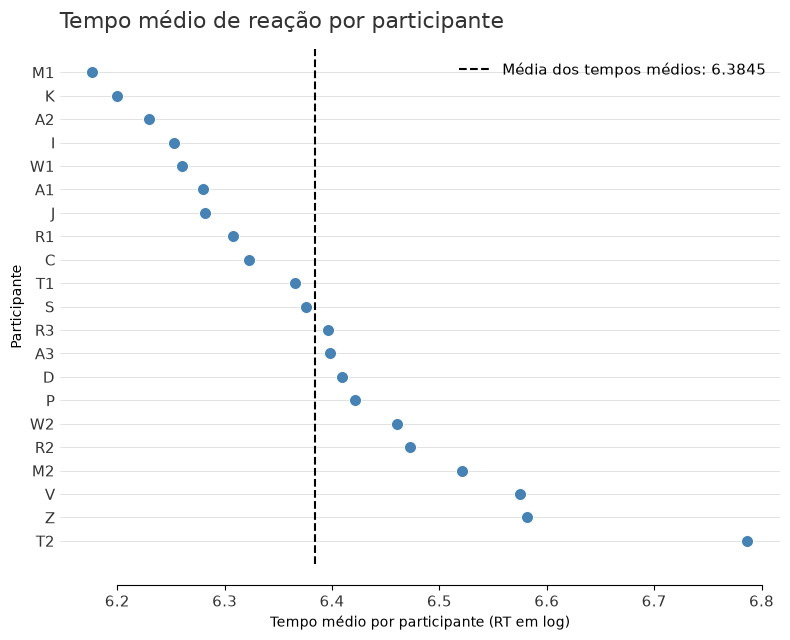

In [18]:
#| label: fig-lexdec-participantes
#| fig-cap: "Tempos médios nas respostas corretas dos 21 participantes, com peso igual por pessoa."
#| fig-alt: "Vinte e um pontos ordenados pelo tempo médio de reação. Uma linha tracejada marca a média dos tempos médios, aproximadamente 6,3845."
#| code-fold: true
#| code-summary: "Mostrar construção do gráfico"

participant_plot_df = participant_df.sort_values("mean_rt")
grand_mean = participant_plot_df["mean_rt"].mean()
fig, ax = plt.subplots(figsize=(8, 6.5))

sns.scatterplot(
    data=participant_plot_df,
    x="mean_rt",
    y="subject",
    color="steelblue",
    edgecolor="white",
    s=75,
    zorder=3,
    ax=ax,
)
ax.axvline(
    grand_mean,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label=f"Média dos tempos médios: {grand_mean:.4f}",
)
ax.set_title(
    "Tempo médio de reação por participante",
    loc="left",
    fontsize=16,
    color="#333333",
    pad=15,
)
ax.set(
    xlabel="Tempo médio por participante (RT em log)", ylabel="Participante"
)
ax.tick_params(axis="y", length=0)
ax.legend(frameon=False, fontsize=11)

ax.tick_params(axis="both", labelsize=11, labelcolor="#333333")
ax.grid(axis="y", alpha=0.4, linewidth=0.4, color="grey")
sns.despine(ax=ax, top=True, left=True, trim=True, offset=15)
fig.tight_layout()
plt.show()

### 3.1 Desvio-padrão e erro padrão

O **desvio-padrão** $s$ descreve quanto os 21 tempos médios variam entre os
participantes observados. O **erro padrão** descreve quanto a estimativa
da média variaria entre amostras geradas pelo mesmo processo.

Para a média de $n$ observações independentes de uma mesma população com
variância finita, podemos estimar o erro padrão por:

$$
\widehat{SE}(\bar{x})=\frac{s}{\sqrt{n}}.
$$

Aqui, as observações são os **tempos médios por participante**, não os 1.594
ensaios. Usaremos o desvio-padrão amostral (`ddof=1`), com $n-1$ no denominador
da variância. A aplicação da fórmula pressupõe que esses resumos possam ser
tratados como unidades independentes para o alvo definido; agregá-los não
verifica esse pressuposto nem o desenho de seleção dos participantes.

In [19]:
#| label: tbl-lexdec-dp-ep
#| tbl-cap: "Média, desvio-padrão e erro padrão: objetos distintos."
#| classes: ["table-responsive"]

participant_mean = participant_df["mean_rt"].mean()
participant_sd = participant_df["mean_rt"].std(ddof=1)
n_participants = len(participant_df)
participant_se_formula = participant_sd / np.sqrt(n_participants)

pd.DataFrame(
    {
        "Medida": [
            "Média dos tempos médios",
            "DP entre tempos médios",
            "EP da média: s / raiz de n",
        ],
        "RT em log": [
            participant_mean,
            participant_sd,
            participant_se_formula,
        ],
    }
).round(4)

,Medida,RT em log
0,Média dos tempos médios,6.3845
1,DP entre tempos médios,0.1479
2,EP da média: s / raiz de n,0.0323


O desvio-padrão entre tempos médios fica perto de 0,148,
enquanto o erro padrão da média fica perto de 0,032. São objetos
diferentes: o primeiro descreve a dispersão observada entre pessoas;
o segundo representa a incerteza de uma estatística sob o modelo de
amostragem. O bootstrap fornecerá outra aproximação para essa incerteza.

## 4. Bootstrap da média

Na primeira parte, reamostramos códigos 0/1 para estudar uma proporção.
Agora aplicaremos o mesmo mecanismo a **21 tempos médios por participante**.
O bootstrap não paramétrico usa a amostra observada como distribuição empírica:
cada uma das 21 pessoas tem a mesma chance de ser sorteada em cada posição.

Sortearemos 21 participantes **com reposição**. Depois de ser sorteada,
uma pessoa continua disponível: pode aparecer novamente, enquanto outra
pode não entrar na reamostragem. O tamanho permanece 21; não coletamos
21 novos participantes.

Começaremos com uma única reamostragem, usando `DataFrame.sample()`.
`replace=True` explicita a reposição e `random_state=rng` usa o gerador
iniciado no começo do notebook. A saída mantém os identificadores para
que possamos acompanhar as repetições.

In [20]:
#| label: lexdec-reamostragem-participantes
#| classes: ["output-scroll"]

bootstrap_participants_once = participant_df.sample(
    n=n_participants,
    replace=True,
    random_state=rng,
)
print(
    "Participantes sorteados: "
    + ", ".join(bootstrap_participants_once["subject"])
)

Participantes sorteados: A2, R1, Z, T1, T1, T1, T2, P, A3, V, M2, P, K, C, W2, T2, R3, M1, V, R1, M2


In [21]:
#| label: lexdec-repeticoes-participantes
#| classes: ["output-scroll"]

participant_multiplicities = bootstrap_participants_once[
    "subject"
].value_counts()
print(
    "Ocorrências por participante sorteado: "
    + "; ".join(
        f"{subject}: {n}" for subject, n in participant_multiplicities.items()
    )
)

Ocorrências por participante sorteado: T1: 3; R1: 2; T2: 2; P: 2; V: 2; M2: 2; A2: 1; Z: 1; A3: 1; K: 1; C: 1; W2: 1; R3: 1; M1: 1


### 4.1 Uma estatística bootstrap

A contagem mostra quantas vezes cada participante entrou na reamostragem.
As frequências somam 21; os participantes ausentes não aparecem nessa saída.
Cada ocorrência contribui uma vez para a média reamostrada, inclusive quando
o mesmo identificador aparece repetidamente.

Calcularemos a média dessa combinação e a compararemos com a estimativa
observada. A diferença corresponde a uma realização da variabilidade sob
reamostragem, sem alterar `participant_df`.

In [22]:
#| label: media-primeira-reamostragem

bootstrap_mean_once = bootstrap_participants_once["mean_rt"].mean()

print(f"Média na primeira reamostragem (RT em log): {bootstrap_mean_once:.4f}")

Média na primeira reamostragem (RT em log): 6.4327


In [23]:
#| label: lexdec-media-uma-reamostragem
#| classes: ["output-scroll"]

print(f"Média observada (RT em log): {participant_mean:.4f}")
print(f"Média na reamostragem (RT em log): {bootstrap_mean_once:.4f}")

Média observada (RT em log): 6.3845
Média na reamostragem (RT em log): 6.4327


A média original é a estimativa observada, $\hat{\theta}$.
A média de uma reamostragem é $\hat{\theta}^{*}$; o asterisco identifica
o resultado bootstrap. O alvo populacional $\theta$ permanece desconhecido.

Uma única $\hat{\theta}^{*}$ mostra como o sorteio funciona. Ela não fornece
uma medida da dispersão entre reamostragens. Para estudar essa dispersão,
precisamos repetir o processo.

### 4.2 Repetição da reamostragem

Em cada repetição, sorteamos 21 tempos médios **com reposição**, calculamos
sua média e guardamos o resultado. Depois de $B$ repetições, teremos:

$$
\hat{\theta}^{*}_1,\hat{\theta}^{*}_2,\ldots,\hat{\theta}^{*}_B.
$$

Esses valores formam a **distribuição bootstrap da média**. Ela aproxima
a distribuição amostral de interesse sob os dados e o esquema escolhidos;
não é a distribuição dos tempos individuais nem a distribuição populacional.

Usaremos $n=21$ participantes e $B=10\,000$ reamostragens. No laço abaixo,
`rng.choice(..., size=n_participants, replace=True)` gera uma reamostragem
completa. A variável `_` indica que não precisamos do número da iteração.
`append()` guarda **uma média por reamostragem**; ao final, convertemos
a lista em um array NumPy.

In [24]:
#| label: bootstrap-media-manual

# Extraímos os tempos médios dos participantes.
participant_values = participant_df["mean_rt"].to_numpy()

# Definimos quantas reamostragens bootstrap vamos gerar.
n_bootstrap = 10_000


# Aqui vamos guardar a média calculada em cada reamostragem.
bootstrap_means = []

for _ in range(n_bootstrap):
    # Sorteamos 21 participantes com reposição.
    bootstrap_sample = rng.choice(
        participant_values,
        size=n_participants,
        replace=True,
    )

    # Calculamos a média da reamostragem.
    bootstrap_mean = bootstrap_sample.mean()

    # Guardamos esse valor.
    bootstrap_means.append(bootstrap_mean)

# Transformamos a lista em array para facilitar análises e gráficos.
bootstrap_means = np.array(bootstrap_means)

### 4.3 Distribuição bootstrap da média

Cada valor em `bootstrap_means` resume uma reamostragem completa de 21
participantes. Portanto, o eixo horizontal da @fig-bootstrap-media mostra
**médias reamostradas**, e o vertical conta quantas delas caem em cada faixa.

O histograma tende a se concentrar perto da média observada, marcada pela
linha tracejada. Sua dispersão mostra como essa estatística varia quando
a composição de participantes muda sob a distribuição empírica.

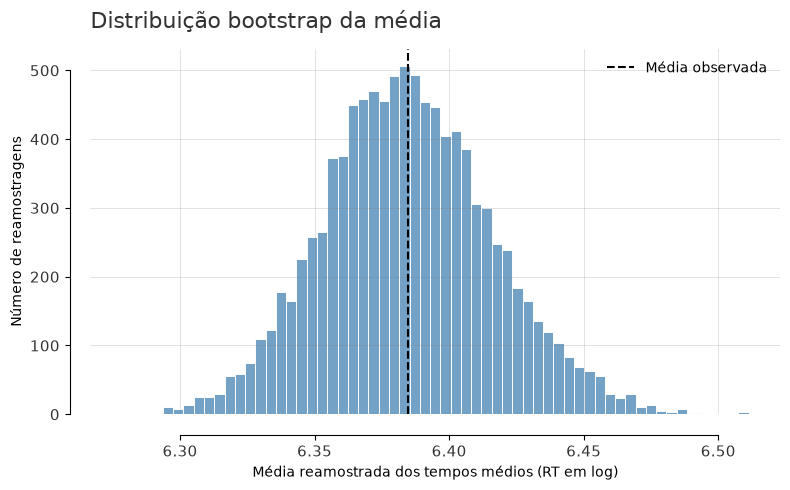

In [25]:
#| label: fig-bootstrap-media
#| fig-cap: "10.000 médias bootstrap, cada uma calculada em uma reamostragem de 21 participantes."
#| fig-alt: "Histograma das médias reamostradas por participante. O eixo horizontal representa médias em log, e o vertical conta reamostragens; a linha tracejada marca a estimativa observada."
#| code-fold: true
#| code-summary: "Mostrar construção do gráfico"

fig, ax = plt.subplots(figsize=(8, 5))

sns.histplot(
    x=bootstrap_means, bins="fd", color="steelblue", edgecolor="white", ax=ax
)
ax.axvline(
    participant_mean,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Média observada",
)
ax.set_title(
    "Distribuição bootstrap da média",
    loc="left",
    fontsize=16,
    color="#333333",
    pad=15,
)
ax.set(
    xlabel="Média reamostrada dos tempos médios (RT em log)",
    ylabel="Número de reamostragens",
)
ax.legend(frameon=False)

ax.tick_params(axis="both", labelsize=11, labelcolor="#333333")
ax.grid(axis="both", alpha=0.4, linewidth=0.4, color="grey")
sns.despine(ax=ax, top=True, left=False, trim=True, offset=15)
fig.tight_layout()
plt.show()

### 4.4 Erro padrão bootstrap

A dispersão das médias reamostradas fornece o **erro padrão bootstrap**.
Se $\bar{\theta}^{*}$ é a média das $B$ estatísticas reamostradas:

$$
\widehat{SE}_{\mathrm{boot}}
=\sqrt{\frac{1}{B-1}\sum_{b=1}^{B}
(\hat{\theta}^{*}_b-\bar{\theta}^{*})^2}.
$$

O somatório percorre as **10.000 estatísticas**, não os 21 tempos médios
originais. `bootstrap_means.std(ddof=1)` executa esse cálculo. Compararemos
o resultado com $s/\sqrt{n}$ na @tbl-lexdec-erros-padrao-media.

In [26]:
#| label: tbl-lexdec-erros-padrao-media
#| tbl-cap: "Erro padrão clássico, valor empírico exato e aproximação bootstrap."
#| classes: ["table-responsive"]

participant_se_bootstrap = bootstrap_means.std(ddof=1)
participant_se_empirical = participant_se_formula * np.sqrt(
    (n_participants - 1) / n_participants
)

pd.DataFrame(
    {
        "Procedimento": [
            "Fórmula: s / raiz de n",
            "Distribuição empírica: valor exato",
            "Bootstrap: 10.000 reamostragens",
        ],
        "EP da média (log)": [
            participant_se_formula,
            participant_se_empirical,
            participant_se_bootstrap,
        ],
    }
).round(4)

,Procedimento,EP da média (log)
0,Fórmula: s / raiz de n,0.0323
1,Distribuição empírica: valor exato,0.0315
2,Bootstrap: 10.000 reamostragens,0.0314


Os dois erros padrão ficam na escala de aproximadamente 0,03 unidades
de RT em log. Eles descrevem a incerteza da média dos resumos por pessoa,
sob os pressupostos já definidos, e não a dispersão dos ensaios individuais.

::: {.callout-note title="Uma diferença de tamanho finito"}
A distribuição empírica atribui peso $1/n$ a cada valor. Sua variância usa
$n$ no denominador, enquanto $s^2$ usa $n-1$. Para a média, o erro padrão
exato sob reamostragem dessa distribuição é:

$$
SE_{\mathrm{emp}}(\bar{x}^{*})
=\frac{s}{\sqrt{n}}\sqrt{\frac{n-1}{n}}.
$$

Com $n=21$, esse valor é um pouco menor que $s/\sqrt{n}$. Além disso,
10.000 sorteios introduzem uma pequena variação computacional.
A diferença não indica que uma das implementações esteja errada.
:::

Essas quantidades permanecem na escala dos logaritmos. Um erro padrão
de 0,03 não equivale a 0,03 milissegundos nem a uma porcentagem de respostas.

### 4.5 Quantas reamostragens são suficientes?

$B$ controla a precisão da **aproximação computacional**. Com poucas
reamostragens, o erro padrão estimado pode oscilar mais; com mais repetições,
tende a se estabilizar. A sequência não precisa melhorar de forma monotônica.

Usaremos os primeiros 100, 250, 500 e demais valores de `bootstrap_means`,
até chegar aos 10.000. Assim, cada cálculo aproveita um prefixo do mesmo
vetor, sem iniciar outra simulação. Os pontos não são análises independentes.

::: {.callout-note title="Mais reamostragens não são mais dados"}
$n=21$ continua a ser o número de participantes. Aumentar $B$ reduz a
variação da simulação, mas não acrescenta informação à amostra nem corrige
viés de seleção, dependência ou uma unidade de reamostragem inadequada.
:::

A @fig-bootstrap-estabilidade acompanha o erro padrão. Essa inspeção não
demonstra, por si só, estabilidade dos quantis das caudas ou cobertura
adequada de um intervalo.

In [27]:
#| label: bootstrap-estabilidade
#| classes: ["output-scroll"]

bootstrap_sizes = [100, 250, 500, 1_000, 2_500, 5_000, 10_000]
standard_error_by_b = [
    bootstrap_means[:size].std(ddof=1) for size in bootstrap_sizes
]

stability_df = pd.DataFrame(
    {"B": bootstrap_sizes, "erro_padrao": standard_error_by_b}
)

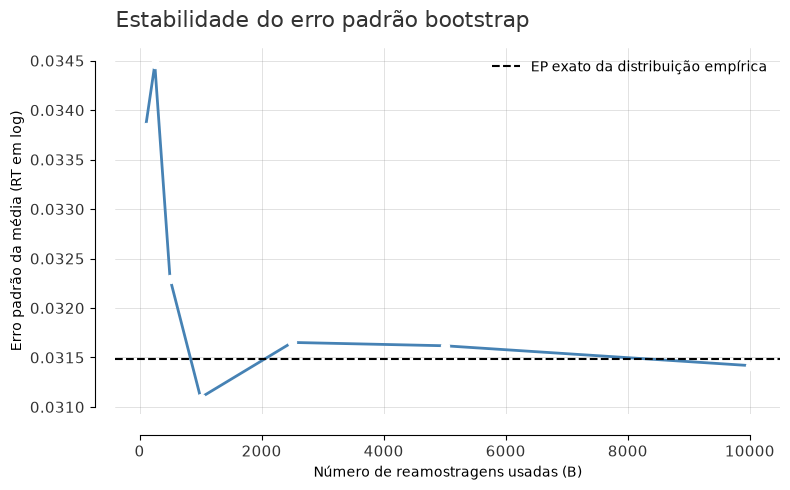

In [28]:
#| label: fig-bootstrap-estabilidade
#| fig-cap: "Erro padrão estimado em prefixos de 100 a 10.000 médias reamostradas; a referência é o valor empírico exato."
#| fig-alt: "Linha com sete erros padrão calculados em prefixos do mesmo vetor bootstrap, comparados a uma linha horizontal tracejada de referência."
#| code-fold: true
#| code-summary: "Mostrar construção do gráfico"

fig, ax = plt.subplots(figsize=(8, 5))

sns.lineplot(
    data=stability_df,
    x="B",
    y="erro_padrao",
    color="steelblue",
    marker="o",
    markerfacecolor="white",
    linewidth=2,
    ax=ax,
)
ax.axhline(
    participant_se_empirical,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="EP exato da distribuição empírica",
)
ax.set_title(
    "Estabilidade do erro padrão bootstrap",
    loc="left",
    fontsize=16,
    color="#333333",
    pad=15,
)
ax.set(
    xlabel="Número de reamostragens usadas (B)",
    ylabel="Erro padrão da média (RT em log)",
)
ax.legend(frameon=False)

ax.tick_params(axis="both", labelsize=11, labelcolor="#333333")
ax.grid(axis="both", alpha=0.4, linewidth=0.4, color="grey")
sns.despine(ax=ax, top=True, left=False, trim=True, offset=15)
fig.tight_layout()
plt.show()

A curva mostra oscilações no erro padrão ao ampliar o prefixo
usado. O resultado com $B=10\,000$ é a estimativa baseada no vetor completo.
Conservaremos essas mesmas 10.000 médias para estudar seu centro e os
limites do intervalo, sem gerar outras apenas para mudar de representação.

### 4.6 Centro da distribuição bootstrap

A média de `bootstrap_means` resume o centro das 10.000 estatísticas.
Para a média aritmética sob este esquema, o centro exato da distribuição
bootstrap condicional é a média observada. A média de um número finito
de sorteios pode ficar ligeiramente afastada dela.

Compararemos os dois valores. Sua proximidade é uma propriedade esperada
do procedimento neste caso; não demonstra ausência de viés na seleção
dos participantes.

In [29]:
#| label: bootstrap-centro
#| classes: ["output-scroll"]

bootstrap_center = bootstrap_means.mean()
print(f"Média observada (RT em log): {participant_mean:.4f}")
print(f"Centro das médias bootstrap (RT em log): {bootstrap_center:.4f}")

Média observada (RT em log): 6.3845
Centro das médias bootstrap (RT em log): 6.3848


## 5. Intervalos de confiança

Já usamos a distribuição bootstrap para estimar um erro padrão. Agora
usaremos seus quantis para construir um **intervalo percentil** bilateral
nominal de 95%, retomando o método apresentado na primeira parte.

Se $\alpha=1-0{,}95=0{,}05$, os limites são:

$$
\left[q_{\alpha/2}(\hat{\theta}^{*}),
q_{1-\alpha/2}(\hat{\theta}^{*})\right].
$$

$q_{0{,}025}$ deixa aproximadamente 2,5% das estatísticas abaixo dele;
$q_{0{,}975}$ deixa aproximadamente 2,5% acima. A faixa central contém
cerca de 95% das **estatísticas reamostradas**. `np.quantile()` recebe
probabilidades entre 0 e 1, por isso usamos 0,025 e 0,975 no cálculo.

Essa construção define os limites; sua interpretação como intervalo
para o parâmetro exige discutir o procedimento e seus pressupostos.

In [30]:
#| label: bootstrap-intervalo-media
#| classes: ["output-scroll"]

confidence_level = 0.95
alpha = 1 - confidence_level

bootstrap_ci_low, bootstrap_ci_high = np.quantile(
    bootstrap_means,
    [alpha / 2, 1 - alpha / 2],
)

print(
    "IC percentil de 95% da média (log): "
    f"[{bootstrap_ci_low:.4f}; {bootstrap_ci_high:.4f}]"
)

IC percentil de 95% da média (log): [6.3252; 6.4499]


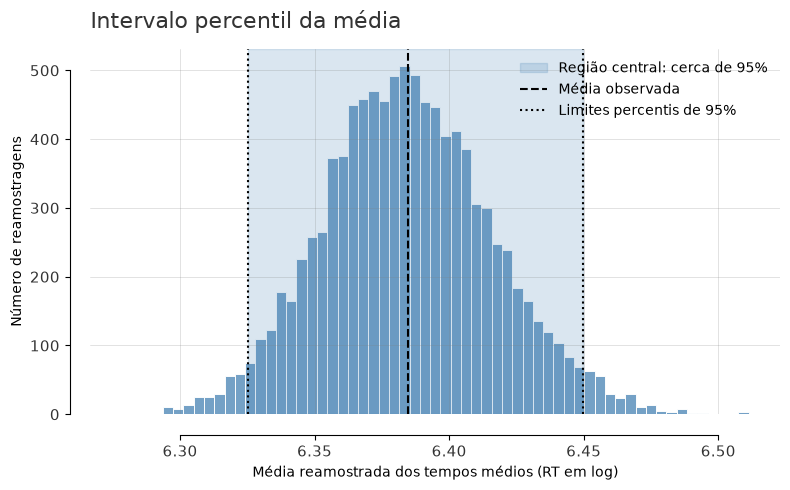

In [31]:
#| label: fig-bootstrap-media-intervalo
#| fig-cap: "Distribuição bootstrap da média, estimativa observada e limites percentis 2,5 e 97,5."
#| fig-alt: "Histograma de médias bootstrap com uma linha tracejada na média observada e duas linhas pontilhadas nos limites do intervalo. A faixa central está sombreada."
#| code-fold: true
#| code-summary: "Mostrar construção do gráfico"

fig, ax = plt.subplots(figsize=(8, 5))

sns.histplot(
    x=bootstrap_means, bins="fd", color="steelblue", edgecolor="white", ax=ax
)
ax.axvspan(
    bootstrap_ci_low,
    bootstrap_ci_high,
    color="steelblue",
    alpha=0.2,
    label="Região central: cerca de 95%",
)
ax.axvline(
    participant_mean,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Média observada",
)
ax.axvline(
    bootstrap_ci_low,
    color="black",
    linestyle=":",
    linewidth=1.5,
    label="Limites percentis de 95%",
)
ax.axvline(bootstrap_ci_high, color="black", linestyle=":", linewidth=1.5)
ax.set_title(
    "Intervalo percentil da média",
    loc="left",
    fontsize=16,
    color="#333333",
    pad=15,
)
ax.set(
    xlabel="Média reamostrada dos tempos médios (RT em log)",
    ylabel="Número de reamostragens",
)
ax.legend(frameon=False)

ax.tick_params(axis="both", labelsize=11, labelcolor="#333333")
ax.grid(axis="both", alpha=0.4, linewidth=0.4, color="grey")
sns.despine(ax=ax, top=True, left=False, trim=True, offset=15)
fig.tight_layout()
plt.show()

### 5.1 O que significa 95% de confiança?

Na @fig-bootstrap-media-intervalo, o sombreamento mostra a região central
da distribuição bootstrap. Essa área resume estatísticas reamostradas,
não uma distribuição de probabilidades do parâmetro populacional.

Na interpretação frequentista, o parâmetro é fixo e os intervalos variam
entre amostras. Se repetíssemos **a coleta e toda a construção do intervalo**,
a meta de um procedimento de 95% seria conter o parâmetro em cerca de 95%
dessas repetições, sob os pressupostos e a adequação do método.

::: {.callout-important title="Nível nominal e cobertura"}
Um intervalo já calculado contém ou não contém o parâmetro. O nível de
95% não atribui uma probabilidade de 95% ao parâmetro fixo dentro deste
intervalo específico. Também não garante cobertura exata com uma amostra
pequena: o intervalo percentil é uma aproximação cuja qualidade depende
da estatística, dos dados e do desenho.
:::

O [NIST discute a interpretação de intervalos de confiança](https://www.itl.nist.gov/div898/handbook/prc/section1/prc14.htm).
O resultado desta oficina é um intervalo para a **média dos tempos médios
por participante**, condicional aos itens observados e ao filtro de acertos.

### 5.2 Intervalo clássico e intervalo bootstrap

Uma construção clássica para a média usa o erro padrão $s/\sqrt{n}$ e
a distribuição $t$ de Student:

$$
\bar{x}\pm t_{0{,}975,\,n-1}\frac{s}{\sqrt{n}}.
$$

$t_{0{,}975,\,n-1}$ é o quantil que deixa 97,5% da distribuição à esquerda;
$n-1=20$ são os graus de liberdade. `stats.t.ppf()` recupera esse valor
crítico. O intervalo é simétrico em torno de $\bar{x}$.

O [intervalo $t$ para a média](https://www.itl.nist.gov/div898/handbook/eda/section3/eda352.htm)
tem cobertura exata sob observações independentes de uma mesma população
normal. Aqui, essa condição diz respeito aos **resumos por participante**,
não à normalidade de cada ensaio. Fora dessa condição, a construção é uma
aproximação; com apenas 21 resumos, sua adequação exige atenção.

O intervalo percentil lê quantis da distribuição bootstrap e pode ser
assimétrico em torno da estimativa. Compararemos as duas construções,
sem tomar sua concordância como prova de validade.

In [32]:
#| label: tbl-lexdec-intervalos-media
#| tbl-cap: "Dois intervalos para a mesma média dos resumos por participante."
#| classes: ["table-responsive"]

t_critical = stats.t.ppf(1 - alpha / 2, df=n_participants - 1)
t_ci_low = participant_mean - t_critical * participant_se_formula
t_ci_high = participant_mean + t_critical * participant_se_formula

interval_comparison = pd.DataFrame(
    {
        "Método": ["t de Student", "Bootstrap percentil"],
        "IC 95% inferior (log)": [t_ci_low, bootstrap_ci_low],
        "IC 95% superior (log)": [t_ci_high, bootstrap_ci_high],
    }
)

interval_comparison.round(4)

,Método,IC 95% inferior (log),IC 95% superior (log)
0,t de Student,6.3172,6.4518
1,Bootstrap percentil,6.3252,6.4499


### 5.3 Como relatar o resultado?

A @tbl-lexdec-intervalos-media apresenta intervalos para o mesmo alvo.
A diferença entre seus limites decorre das construções: um usa o valor
crítico $t$ e o erro padrão clássico; o outro usa os quantis reamostrados.

Um relato deve indicar a estimativa, sua escala, o método, o nível e
a unidade reamostrada. Podemos construir esse relato com os valores
efetivamente calculados, evitando copiar limites de uma execução anterior.

In [33]:
#| echo: false

display(
    Markdown(
        "A média dos tempos médios dos "
        f"**{n_participants} participantes** foi "
        f"**{participant_mean:.4f}**, na escala logarítmica fornecida. "
        "O bootstrap de participantes, com "
        f"**{n_bootstrap} reamostragens**, "
        f"estimou erro padrão de **{participant_se_bootstrap:.4f}** "
        "e intervalo percentil nominal de 95% de "
        f"**{bootstrap_ci_low:.4f} a {bootstrap_ci_high:.4f}**, "
        "condicional aos itens observados e às respostas corretas."
    )
)

A média dos tempos médios dos **21 participantes** foi **6.3845**, na escala logarítmica fornecida. O bootstrap de participantes, com **10000 reamostragens**, estimou erro padrão de **0.0314** e intervalo percentil nominal de 95% de **6.3252 a 6.4499**, condicional aos itens observados e às respostas corretas.

::: {.callout-warning title="Seleção dos participantes"}
A interpretação populacional depende de como os participantes foram
selecionados e do processo que se pretende representar. O bootstrap
quantifica incerteza sob o esquema escolhido; não transforma uma amostra
não representativa em uma amostra representativa.
:::

## 6. Bootstrap da mediana

O mesmo mecanismo pode estudar outra estatística. Manteremos os 21 tempos
médios, a unidade de reamostragem e o número de repetições; em cada
reamostragem, calcularemos a **mediana** em vez da média.

Essa mudança altera o alvo: a mediana descreve a posição central dos
resumos por pessoa. O erro padrão da média, $s/\sqrt{n}$, não fornece
automaticamente o erro padrão da mediana.

### 6.1 Mediana dos tempos médios

Ordenando os 21 tempos médios, a mediana é o 11º valor. Ela é menos
sensível que a média à magnitude de valores afastados, mas ainda depende
dos dados observados e de sua ordenação.

Nesta amostra, a média é aproximadamente 6,3845 e a mediana, 6,3759.
Ambas resumem os **tempos médios por participante**; a mediana desses
resumos não é a mediana de todos os ensaios. Compararemos sua incerteza
sem presumir que menor sensibilidade implique um intervalo mais estreito.

In [34]:
#| label: lexdec-media-mediana-observadas
#| classes: ["output-scroll"]

participant_median = participant_df["mean_rt"].median()
print(f"Média dos tempos médios (log): {participant_mean:.4f}")
print(f"Mediana dos tempos médios (log): {participant_median:.4f}")

Média dos tempos médios (log): 6.3845
Mediana dos tempos médios (log): 6.3759


### 6.2 Reamostragem e cálculo da mediana

Em cada repetição, sortearemos 21 tempos médios com reposição e
calcularemos sua mediana. O laço muda a função aplicada, mantendo a
unidade e o tamanho da reamostragem. Continuaremos usando o **mesmo `rng`**,
a partir do estado deixado pelos sorteios anteriores.

Guardaremos $B$ medianas bootstrap,
$\tilde{x}^{*}_1,\ldots,\tilde{x}^{*}_B$. Depois representaremos média e
mediana por ECDFs, como no [Encontro 9](../encontro_9/enc_9.ipynb).
O eixo vertical será a proporção acumulada das estatísticas reamostradas;
o horizontal continuará na escala de RT em log.

In [35]:
#| label: bootstrap-mediana-manual

# Aqui vamos guardar a mediana de cada reamostragem.
bootstrap_medians = []

for _ in range(n_bootstrap):
    # Sorteamos 21 participantes com reposição.
    bootstrap_sample = rng.choice(
        participant_values,
        size=n_participants,
        replace=True,
    )

    # Calculamos a mediana da reamostragem.
    bootstrap_median = np.median(bootstrap_sample)

    # Guardamos o resultado.
    bootstrap_medians.append(bootstrap_median)

# Convertendo a lista em array.
bootstrap_medians = np.array(bootstrap_medians)

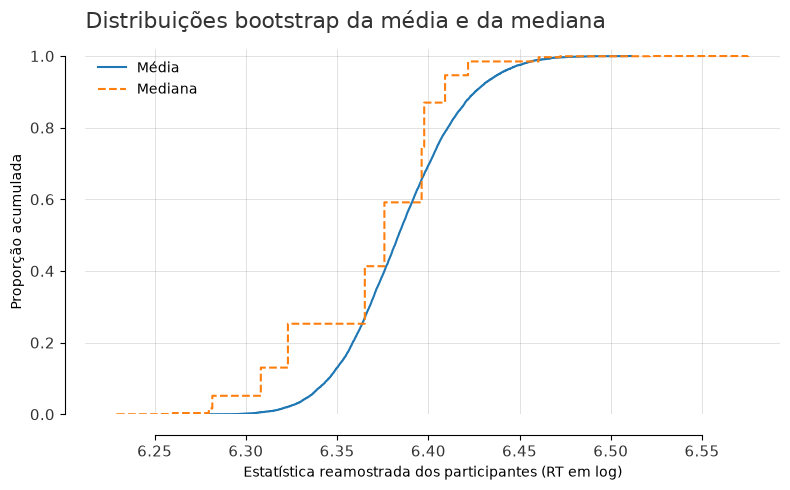

In [36]:
#| label: fig-bootstrap-media-mediana
#| fig-cap: "ECDFs de 10.000 médias e 10.000 medianas bootstrap dos tempos médios por participante."
#| fig-alt: "Duas ECDFs: a média em azul contínuo e a mediana em laranja tracejado. A curva da mediana tem saltos maiores, pois suas estatísticas assumem valores observados."
#| code-fold: true
#| code-summary: "Mostrar construção do gráfico"

comparison_colors = sns.color_palette("tab10", n_colors=2)
fig, ax = plt.subplots(figsize=(8, 5))

sns.ecdfplot(
    x=bootstrap_means, color=comparison_colors[0], label="Média", ax=ax
)
sns.ecdfplot(
    x=bootstrap_medians,
    color=comparison_colors[1],
    linestyle="--",
    label="Mediana",
    ax=ax,
)
ax.set_title(
    "Distribuições bootstrap da média e da mediana",
    loc="left",
    fontsize=16,
    color="#333333",
    pad=15,
)
ax.set(
    xlabel="Estatística reamostrada dos participantes (RT em log)",
    ylabel="Proporção acumulada",
    ylim=(0, 1.02),
)
ax.legend(frameon=False)

ax.tick_params(axis="both", labelsize=11, labelcolor="#333333")
ax.grid(axis="both", alpha=0.4, linewidth=0.4, color="grey")
sns.despine(ax=ax, top=True, left=False, trim=True, offset=15)
fig.tight_layout()
plt.show()

### 6.3 Incerteza da mediana

Na @fig-bootstrap-media-mediana, a ECDF das medianas forma saltos mais
visíveis. Como cada reamostragem tem 21 valores, sua mediana precisa
coincidir com um dos tempos médios observados. Já a média pode assumir
valores intermediários. Uma ECDF mais suave não significa que a
estatística correspondente seja necessariamente mais adequada.

Estimaremos o erro padrão pelo desvio-padrão das medianas reamostradas
e construiremos outro intervalo percentil de 95%. Com poucos valores
distintos disponíveis para a mediana, os limites podem mudar em saltos;
aumentar $B$ não remove essa limitação da amostra.

In [37]:
#| label: tbl-lexdec-media-mediana
#| tbl-cap: "Estimativas e incerteza bootstrap da média e da mediana; RT em log."
#| classes: ["table-responsive"]

# Erro padrão bootstrap da mediana.
participant_median_se_bootstrap = bootstrap_medians.std(ddof=1)

# Intervalo percentual de 95% para a mediana.
bootstrap_median_ci_low, bootstrap_median_ci_high = np.quantile(
    bootstrap_medians,
    [alpha / 2, 1 - alpha / 2],
)


# Comparamos as estimativas e a incerteza da média e da mediana.
bootstrap_summary = pd.DataFrame(
    {
        "estatistica": ["Média", "Mediana"],
        "estimativa_observada": [
            participant_mean,
            participant_median,
        ],
        "erro_padrao_bootstrap": [
            participant_se_bootstrap,
            participant_median_se_bootstrap,
        ],
        "ic_95_inferior": [
            bootstrap_ci_low,
            bootstrap_median_ci_low,
        ],
        "ic_95_superior": [
            bootstrap_ci_high,
            bootstrap_median_ci_high,
        ],
    }
)

bootstrap_summary.rename(
    columns={
        "estatistica": "Estatística",
        "estimativa_observada": "Estimativa",
        "erro_padrao_bootstrap": "EP bootstrap",
        "ic_95_inferior": "IC 95% inferior",
        "ic_95_superior": "IC 95% superior",
    },
).round(4)

,Estatística,Estimativa,EP bootstrap,IC 95% inferior,IC 95% superior
0,Média,6.3845,0.0314,6.3252,6.4499
1,Mediana,6.3759,0.0396,6.2816,6.4218


Na @tbl-lexdec-media-mediana, o erro padrão da mediana fica
perto de 0,040, maior que o da média, perto de 0,031. As posições centrais
observadas são próximas, mas a ordenação que determina a mediana muda
em saltos entre reamostragens. Comparar os intervalos documenta essa
diferença de incerteza, sem transformar um dos resumos em substituto universal
do outro.

## 7. Frequência lexical e tempo de reação

Agora mudamos a unidade e a pergunta:

> **Como frequência lexical e tempo médio de reação se associam entre
> as palavras observadas?**

Em `word_df`, cada linha contém uma palavra, seu tempo médio nos ensaios
corretos, a frequência lexical e a quantidade de respostas que contribuíram
para o resumo. Cada palavra fornecerá **um par**, sem ponderar a correlação
por `n_correct`.

Inspecionaremos essas três colunas antes de quantificar a associação.
A frequência e o RT permanecem em logaritmos, conforme o arquivo original.

In [38]:
#| label: lexdec-resumo-palavras
#| classes: ["output-scroll"]

print(f"Palavras: {len(word_df)}")
print(
    "Frequência lexical em log: "
    f"de {word_df['frequency_log'].min():.3f} "
    f"a {word_df['frequency_log'].max():.3f}"
)
print(
    "Tempo médio por palavra em log: "
    f"de {word_df['mean_rt'].min():.3f} a {word_df['mean_rt'].max():.3f}"
)
print(
    "Respostas corretas por palavra: "
    f"de {word_df['n_correct'].min()} a {word_df['n_correct'].max()}"
)

Palavras: 79
Frequência lexical em log: de 1.792 a 7.772
Tempo médio por palavra em log: de 6.245 a 6.640
Respostas corretas por palavra: de 14 a 21


### 7.1 Associação monotônica e correlação de Spearman

Retomamos a [correlação de Spearman](../encontro_8/enc_8.ipynb): ela
quantifica se valores maiores de uma variável tendem a acompanhar valores
sistematicamente maiores ou menores da outra. Usa os **postos** das duas
variáveis, com postos médios em caso de empate:

$$
\hat{\rho}_s
=\operatorname{cor}\left(R_{\mathrm{frequência}},R_{\mathrm{RT}}\right).
$$

Valores próximos de $-1$ indicam associação monotônica negativa forte;
valores próximos de $1$, associação positiva forte. Os logaritmos alteram
distâncias, mas preservam a ordenação das medidas, por serem transformações
estritamente crescentes.

Calcularemos o coeficiente das 79 palavras e o mostraremos junto dos pares
na @fig-lexdec-frequencia. Usaremos `statistic` do objeto retornado por
`stats.spearmanr()`; nosso objetivo é estimar a associação e sua incerteza,
sem desenvolver um teste de hipótese nesta oficina.

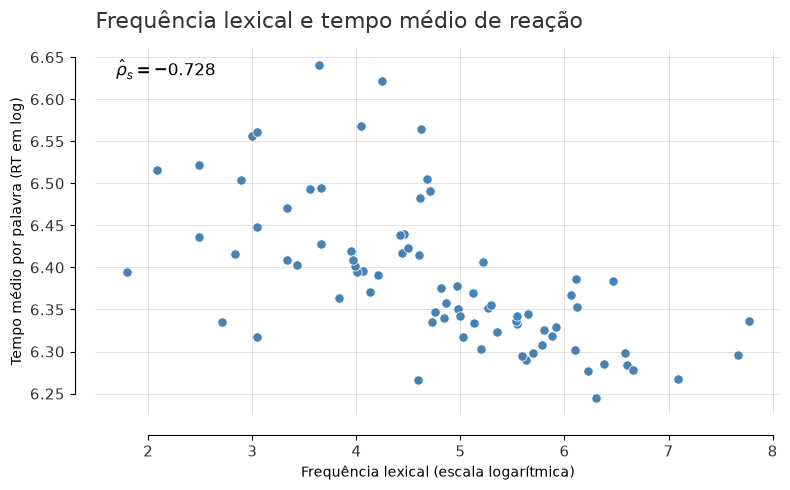

In [39]:
#| label: fig-lexdec-frequencia
#| fig-cap: "Frequência lexical e tempo médio de reação nos ensaios corretos de 79 palavras."
#| fig-alt: "Cada ponto representa uma palavra. Frequências maiores tendem a acompanhar tempos médios menores; a anotação informa Spearman próximo de menos 0,728."
#| code-fold: true
#| code-summary: "Mostrar construção do gráfico"

observed_rho = stats.spearmanr(
    word_df["frequency_log"], word_df["mean_rt"]
).statistic
fig, ax = plt.subplots(figsize=(8, 5))

sns.scatterplot(
    data=word_df,
    x="frequency_log",
    y="mean_rt",
    color="steelblue",
    edgecolor="white",
    s=45,
    ax=ax,
)
ax.set_title(
    "Frequência lexical e tempo médio de reação",
    loc="left",
    fontsize=16,
    color="#333333",
    pad=15,
)
ax.set(
    xlabel="Frequência lexical (escala logarítmica)",
    ylabel="Tempo médio por palavra (RT em log)",
)
ax.text(
    0.03,
    0.97,
    rf"$\hat{{\rho}}_s = {observed_rho:.3f}$",
    transform=ax.transAxes,
    va="top",
    fontsize=12,
)

ax.tick_params(axis="both", labelsize=11, labelcolor="#333333")
ax.grid(axis="both", alpha=0.4, linewidth=0.4, color="grey")
sns.despine(ax=ax, top=True, left=False, trim=True, offset=15)
fig.tight_layout()
plt.show()

### 7.2 Preservando os pares

O coeficiente observado é aproximadamente $-0{,}728$: palavras de maior
frequência tendem a apresentar tempos médios menores nesta amostra.
O gráfico mostra a dispersão ao redor desse padrão. A associação entre
itens não identifica um efeito causal da frequência; outras características
das palavras e do experimento podem participar da relação.

Cada frequência está associada ao tempo médio da **mesma palavra**.
Por isso, sortearemos linhas inteiras de `word_df`, preservando os pares.
Sorteios separados dos dois vetores poderiam combinar a frequência de
uma palavra com o tempo de outra e desfazer a associação que queremos estudar.

Primeiro faremos uma única reamostragem de 79 linhas, recalcularemos
Spearman e inspecionaremos palavras repetidas. Mostraremos oito posições
do sorteio; o coeficiente usará todas as 79.

In [40]:
#| label: lexdec-reamostragem-palavras
#| classes: ["output-scroll"]

n_words = len(word_df)
bootstrap_words_once = word_df.sample(
    n=n_words,
    replace=True,
    random_state=rng,
)
print(
    "Primeiras oito palavras sorteadas: "
    + ", ".join(bootstrap_words_once["word"].head(8))
)

Primeiras oito palavras sorteadas: vulture, dog, grape, cherry, woodpecker, horse, cucumber, elephant


In [41]:
#| label: lexdec-spearman-uma-reamostragem
#| classes: ["output-scroll"]

bootstrap_rho_once = stats.spearmanr(
    bootstrap_words_once["frequency_log"],
    bootstrap_words_once["mean_rt"],
).statistic
print(f"Spearman observado: {observed_rho:.4f}")
print(f"Spearman na reamostragem: {bootstrap_rho_once:.4f}")

Spearman observado: -0.7276
Spearman na reamostragem: -0.7636


In [42]:
#| label: lexdec-repeticoes-palavras
#| classes: ["output-scroll"]

word_multiplicities = bootstrap_words_once["word"].value_counts().head(8)
print(
    "Ocorrências em oito palavras sorteadas: "
    + "; ".join(f"{word}: {n}" for word, n in word_multiplicities.items())
)

Ocorrências em oito palavras sorteadas: beaver: 4; vulture: 3; dog: 3; radish: 3; melon: 3; gherkin: 3; grape: 2; cherry: 2


### 7.3 Distribuição bootstrap de Spearman

A reamostragem anterior conserva 79 posições, mas algumas palavras entram
mais de uma vez. Seu coeficiente pode mudar porque mudou a composição dos
pares. Para medir essa variação, repetiremos o procedimento $B=10\,000$ vezes:

1. sortear 79 posições de `word_df` com reposição;
2. recuperar as linhas completas com `.iloc[]`;
3. recalcular Spearman, incluindo a nova ordenação e seus empates;
4. guardar um coeficiente por reamostragem.

O resultado será a sequência
$\hat{\rho}^{*}_{s,1},\ldots,\hat{\rho}^{*}_{s,B}$.
Sorteamos **posições** entre 0 e 78, e não valores de frequência ou RT
separadamente. O gerador compartilhado continua a controlar os sorteios.

In [43]:
#| label: bootstrap-spearman-manual

# Aqui vamos guardar a correlação de cada reamostragem.
bootstrap_rhos = []

for _ in range(n_bootstrap):
    # Sorteamos posições das 79 palavras com reposição.
    sampled_indices = rng.choice(
        n_words,
        size=n_words,
        replace=True,
    )

    # Selecionamos as linhas completas correspondentes às posições sorteadas.
    bootstrap_words = word_df.iloc[sampled_indices]

    # Recalculamos Spearman preservando os pares frequência–tempo.
    bootstrap_rho = stats.spearmanr(
        bootstrap_words["frequency_log"],
        bootstrap_words["mean_rt"],
    ).statistic

    # Guardamos a correlação da reamostragem.
    bootstrap_rhos.append(bootstrap_rho)

# Transformamos a lista em array.
bootstrap_rhos = np.array(bootstrap_rhos)

### 7.4 Incerteza por item lexical

Neste bootstrap, variamos a composição das **palavras**, enquanto seus
tempos médios permanecem fixos. Estimaremos o erro padrão dos coeficientes
e seu intervalo percentil de 95%, na mesma escala adimensional de Spearman.

Essa incerteza representa a variação entre itens sob o esquema escolhido.
Não incorpora simultaneamente a incerteza dos participantes que contribuíram
para os tempos médios nem demonstra que as 79 palavras sejam uma amostra
representativa de todo o léxico.

In [44]:
#| label: lexdec-spearman-manual
#| classes: ["output-scroll"]

spearman_se_bootstrap = bootstrap_rhos.std(ddof=1)
spearman_ci_low, spearman_ci_high = np.quantile(
    bootstrap_rhos,
    [alpha / 2, 1 - alpha / 2],
)

print(f"Spearman observado: {observed_rho:.4f}")
print(f"Erro padrão bootstrap: {spearman_se_bootstrap:.4f}")
print(f"IC percentil de 95%: [{spearman_ci_low:.4f}; {spearman_ci_high:.4f}]")

Spearman observado: -0.7276
Erro padrão bootstrap: 0.0611
IC percentil de 95%: [-0.8283; -0.5898]


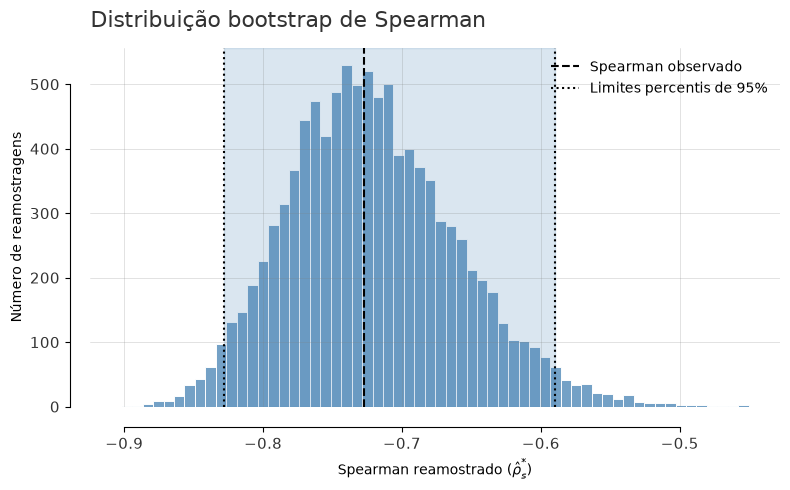

In [45]:
#| label: fig-bootstrap-spearman
#| fig-cap: "10.000 coeficientes de Spearman sob reamostragem de pares por palavra, com intervalo percentil de 95%."
#| fig-alt: "Histograma dos coeficientes de Spearman reamostrados. O coeficiente observado e os dois limites do intervalo ficam no lado negativo."
#| code-fold: true
#| code-summary: "Mostrar construção do gráfico"

fig, ax = plt.subplots(figsize=(8, 5))

sns.histplot(
    x=bootstrap_rhos, bins="fd", color="steelblue", edgecolor="white", ax=ax
)
ax.axvspan(spearman_ci_low, spearman_ci_high, color="steelblue", alpha=0.2)
ax.axvline(
    observed_rho,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Spearman observado",
)
ax.axvline(
    spearman_ci_low,
    color="black",
    linestyle=":",
    linewidth=1.5,
    label="Limites percentis de 95%",
)
ax.axvline(spearman_ci_high, color="black", linestyle=":", linewidth=1.5)
ax.set_title(
    "Distribuição bootstrap de Spearman",
    loc="left",
    fontsize=16,
    color="#333333",
    pad=15,
)
ax.set(
    xlabel=r"Spearman reamostrado ($\hat{\rho}_s^{*}$)",
    ylabel="Número de reamostragens",
)
ax.legend(frameon=False)

ax.tick_params(axis="both", labelsize=11, labelcolor="#333333")
ax.grid(axis="both", alpha=0.4, linewidth=0.4, color="grey")
sns.despine(ax=ax, top=True, left=False, trim=True, offset=15)
fig.tight_layout()
plt.show()

Na @fig-bootstrap-spearman, os coeficientes reamostrados
concentram-se no lado negativo. O intervalo percentil também fica abaixo
de zero. A composição de itens modifica a magnitude estimada, mas a
associação permanece negativa dentro dessa faixa. A interpretação continua
condicional aos tempos médios observados por palavra e ao esquema de itens.

## 8. Dependência e unidade de reamostragem

Até agora, reamostramos resumos por participante e depois pares por palavra.
Retornaremos aos ensaios para comparar três esquemas aplicados à **mesma
média de RT**. Isso permite examinar o efeito da unidade de reamostragem
sem confundi-lo com uma mudança da estatística.

Cada resposta do LexDec pertence simultaneamente a uma pessoa e a um item.
Respostas da mesma pessoa compartilham características do participante;
respostas à mesma palavra compartilham características do item. Há,
portanto, duas dimensões de agrupamento, cruzadas entre si.

O número de linhas não equivale automaticamente ao número de unidades
independentes. Um bootstrap por linhas pode produzir um intervalo estreito
ao representar inadequadamente essa dependência.

### 8.1 Uma nova estatística

Agora o alvo descritivo é a **média de todos os ensaios corretos**, com
o mesmo peso para cada resposta. Na primeira análise, o peso era igual
por pessoa. Se $m_i$ é a quantidade de acertos do participante $i$:

$$
\bar{x}_{\mathrm{ensaios}}
=\frac{\sum_i m_i\bar{x}_i}{\sum_i m_i},
$$

$$
\bar{x}_{\mathrm{participantes}}
=\frac{1}{n}\sum_i\bar{x}_i.
$$

Os dois cálculos coincidiriam se todos contribuíssem o mesmo número de
respostas, mas o filtro de acertos deixa contagens entre 67 e 79 por pessoa.
A diferença observada é pequena; os alvos continuam distintos.
Também conferiremos as contagens por palavra, que vão de 14 a 21.

In [46]:
#| label: tbl-lexdec-pesos
#| tbl-cap: "Peso igual por ensaio ou por participante: estatísticas diferentes."
#| classes: ["table-responsive"]

trial_mean = correct_df["rt_log"].mean()
participant_weighted_mean = participant_df["mean_rt"].mean()

pd.DataFrame(
    {
        "Peso igual por": ["Ensaio correto", "Participante"],
        "Estimativa (log)": [trial_mean, participant_weighted_mean],
    }
).round(4)

,Peso igual por,Estimativa (log)
0,Ensaio correto,6.3839
1,Participante,6.3845


In [47]:
#| label: lexdec-acertos-por-pessoa
#| classes: ["output-scroll"]

print(
    "Respostas corretas por participante: "
    f"de {participant_df['n_correct'].min()} "
    f"a {participant_df['n_correct'].max()}"
)

Respostas corretas por participante: de 67 a 79


In [48]:
#| label: lexdec-acertos-por-palavra
#| classes: ["output-scroll"]

print(
    "Respostas corretas por palavra: "
    f"de {word_df['n_correct'].min()} a {word_df['n_correct'].max()}"
)

Respostas corretas por palavra: de 14 a 21


### 8.2 Bootstrap por linhas

Começaremos sorteando 1.594 ensaios corretos com reposição e recalculando
a média em cada repetição. Esse esquema trata cada linha como uma unidade
independente e intercambiável.

::: {.callout-warning title="Um esquema de comparação"}
O sorteio de linhas ignora os agrupamentos por participante e por palavra.
Aqui ele serve para comparar mecanismos de reamostragem, não para recomendar
que os 1.594 ensaios sejam tratados como 1.594 unidades independentes.
:::

Guardaremos as médias em `bootstrap_trial_means` e calcularemos seu
desvio-padrão. O gerador e o número $B$ permanecem os mesmos.

In [49]:
#| label: bootstrap-linhas
#| classes: ["output-scroll"]

# Extraímos os tempos de reação de todos os ensaios corretos.
trial_values = correct_df["rt_log"].to_numpy()

# Média observada quando cada ensaio recebe o mesmo peso.
observed_trial_mean = trial_values.mean()


# Aqui vamos guardar uma média por reamostragem.
bootstrap_trial_means = []

for _ in range(n_bootstrap):
    # Sorteamos ensaios individuais com reposição.
    bootstrap_sample = rng.choice(
        trial_values,
        size=len(trial_values),
        replace=True,
    )

    # Calculamos e guardamos a média da reamostragem.
    bootstrap_trial_means.append(bootstrap_sample.mean())

bootstrap_trial_means = np.array(bootstrap_trial_means)

# Erro padrão sob o esquema de reamostragem por linhas.
trial_bootstrap_se = bootstrap_trial_means.std(ddof=1)

print(f"Média dos ensaios (log): {observed_trial_mean:.4f}")
print(f"EP bootstrap por linhas (log): {trial_bootstrap_se:.4f}")

Média dos ensaios (log): 6.3839
EP bootstrap por linhas (log): 0.0059


O erro padrão por linhas fica na escala de 0,006. Esse valor
descreve o esquema que acabamos de executar. Para avaliar a importância
dos agrupamentos, precisamos compará-lo com sorteios que preservem
respostas da mesma pessoa ou do mesmo item.

### 8.3 Bootstrap por participante

Agora sortearemos **21 grupos de participantes**. Quando uma pessoa entra,
todas as suas respostas corretas entram juntas. Se ela for sorteada duas
vezes, o conjunto completo entra duas vezes.

Para calcular a média dos ensaios, bastam dois resumos por grupo: a soma
de `rt_log` (`rt_sum`) e a quantidade de respostas (`n_trials`). Esses
resumos preservam exatamente a contribuição do grupo para **esta média**.

Se $S_g$ e $m_g$ são a soma e a contagem do grupo $g$, e $g_1^*,\ldots,g_n^*$
são os grupos sorteados, calculamos:

$$
\bar{x}^{*}_{\mathrm{ensaios}}
=\frac{\sum_{j=1}^{n}S_{g_j^*}}{\sum_{j=1}^{n}m_{g_j^*}}.
$$

Sorteamos grupos com probabilidades iguais; dentro do cálculo, cada
ensaio tem o mesmo peso. Como as contagens diferem, o total de ensaios
pode variar entre reamostragens, embora sejam sempre sorteados 21 grupos.
Uma simples média das médias dos grupos mudaria a estatística.

In [50]:
#| label: lexdec-grupos-participantes
#| classes: ["output-scroll"]

# Resumimos os ensaios de cada participante.
participant_clusters = correct_df.groupby("subject", as_index=False).agg(
    rt_sum=("rt_log", "sum"),
    n_trials=("rt_log", "size"),
)

first_cluster = participant_clusters.iloc[0]
print(f"Primeiro grupo: {first_cluster['subject']}")
print(f"Soma de RT em log: {first_cluster['rt_sum']:.4f}")
print(f"Ensaios corretos no grupo: {first_cluster['n_trials']}")

Primeiro grupo: A1
Soma de RT em log: 489.8163
Ensaios corretos no grupo: 78


In [51]:
#| label: media-reconstruida-participantes

# Reconstruímos a média de todos os ensaios a partir dos grupos.
participant_trial_mean = (
    participant_clusters["rt_sum"].sum()
    / participant_clusters["n_trials"].sum()
)

print(
    "Média dos ensaios reconstruída dos grupos (log): "
    f"{participant_trial_mean:.4f}"
)

Média dos ensaios reconstruída dos grupos (log): 6.3839


In [52]:
#| label: bootstrap-grupos-participantes
#| classes: ["output-scroll"]

participant_cluster_means = []

for _ in range(n_bootstrap):
    # Sorteamos 21 posições de participantes com reposição.
    sampled_positions = rng.choice(
        len(participant_clusters),
        size=len(participant_clusters),
        replace=True,
    )

    # Recuperamos os grupos completos correspondentes.
    sampled_clusters = participant_clusters.iloc[sampled_positions]

    # Reconstruímos a média de todos os ensaios dos grupos sorteados.
    bootstrap_mean = (
        sampled_clusters["rt_sum"].sum() / sampled_clusters["n_trials"].sum()
    )

    participant_cluster_means.append(bootstrap_mean)

participant_cluster_means = np.array(participant_cluster_means)

# Erro padrão sob reamostragem de participantes.
participant_cluster_se = participant_cluster_means.std(ddof=1)


print(f"Média reconstruída dos ensaios (log): {participant_trial_mean:.4f}")
print(f"EP bootstrap por participantes (log): {participant_cluster_se:.4f}")

Média reconstruída dos ensaios (log): 6.3839
EP bootstrap por participantes (log): 0.0307


### 8.4 Bootstrap por palavra

Repetiremos o procedimento com **79 grupos de palavras**. Todas as respostas
corretas ao item sorteado permanecem juntas; itens repetidos na reamostragem
contribuem com seu grupo completo a cada ocorrência.

Novamente somaremos `rt_sum` e dividiremos pela soma de `n_trials`.
A reconstrução dos dados observados deve recuperar a mesma média dos ensaios,
embora a fonte de variação agora seja a composição de palavras. Os
participantes observados permanecem no conjunto de respostas de cada item.

In [53]:
#| label: lexdec-grupos-palavras
#| classes: ["output-scroll"]

# Resumimos os ensaios associados a cada palavra.
word_clusters = correct_df.groupby("word", as_index=False).agg(
    rt_sum=("rt_log", "sum"),
    n_trials=("rt_log", "size"),
)

first_cluster = word_clusters.iloc[0]
print(f"Primeiro grupo: {first_cluster['word']}")
print(f"Soma de RT em log: {first_cluster['rt_sum']:.4f}")
print(f"Ensaios corretos no grupo: {first_cluster['n_trials']}")

Primeiro grupo: almond
Soma de RT em log: 121.4261
Ensaios corretos no grupo: 19


In [54]:
#| label: media-reconstruida-palavras

# Reconstruímos a média de todos os ensaios a partir dos grupos por palavra.
word_trial_mean = (
    word_clusters["rt_sum"].sum() / word_clusters["n_trials"].sum()
)

print(
    f"Média dos ensaios reconstruída dos grupos (log): {word_trial_mean:.4f}"
)

Média dos ensaios reconstruída dos grupos (log): 6.3839


In [55]:
#| label: bootstrap-grupos-palavras

word_cluster_means = []

for _ in range(n_bootstrap):
    # Sorteamos 79 palavras com reposição.
    sampled_positions = rng.choice(
        len(word_clusters),
        size=len(word_clusters),
        replace=True,
    )

    # Recuperamos os grupos correspondentes.
    sampled_clusters = word_clusters.iloc[sampled_positions]

    # Reconstruímos a média dos ensaios das palavras sorteadas.
    bootstrap_mean = (
        sampled_clusters["rt_sum"].sum() / sampled_clusters["n_trials"].sum()
    )

    word_cluster_means.append(bootstrap_mean)

word_cluster_means = np.array(word_cluster_means)

# Erro padrão sob reamostragem de palavras.
word_cluster_se = word_cluster_means.std(ddof=1)

In [56]:
#| label: lexdec-esquemas
#| classes: ["output-scroll"]

resampling_comparison = pd.DataFrame(
    {
        "esquema": ["Linhas", "Participantes", "Palavras"],
        "media_observada": [
            observed_trial_mean,
            participant_trial_mean,
            word_trial_mean,
        ],
        "erro_padrao_bootstrap": [
            trial_bootstrap_se,
            participant_cluster_se,
            word_cluster_se,
        ],
    }
)
print(f"Média dos ensaios nos três esquemas (log): {observed_trial_mean:.4f}")
print(f"EP por linhas (log): {trial_bootstrap_se:.4f}")
print(f"EP por participantes (log): {participant_cluster_se:.4f}")
print(f"EP por palavras (log): {word_cluster_se:.4f}")

Média dos ensaios nos três esquemas (log): 6.3839
EP por linhas (log): 0.0059
EP por participantes (log): 0.0307
EP por palavras (log): 0.0093


### 8.5 O que cada esquema representa?

Na comparação dos esquemas, os três cálculos reconstroem a média observada
dos ensaios, aproximadamente 6,3839. A estimativa é a mesma; a dispersão
das médias reamostradas muda com a unidade sorteada.

Neste conjunto, o erro padrão por linhas fica perto de 0,006, por
participantes, de 0,031, e por palavras, de 0,009. O agrupamento por pessoa
representa uma fonte de variação que o sorteio individual de ensaios perde.
Essa ordem é um resultado destes dados, não uma regra universal sobre
bootstraps por grupos.

### 8.6 Alcance dos esquemas de reamostragem

**Linhas:** sorteiam ensaios individualmente, sem manter agrupamentos.

**Participantes:** sorteiam pessoas com suas respostas corretas, preservando
o conjunto de respostas da mesma pessoa.

**Palavras:** sorteiam itens com suas respostas corretas, preservando
o conjunto de respostas ao mesmo item.

::: {.callout-important title="Duas dimensões de dependência"}
O LexDec tem participantes e palavras cruzados. Reamostrar apenas pessoas
ou apenas palavras representa uma dimensão da variação, mantendo a outra
observada. Generalizar simultaneamente para novos participantes e novos
itens exige métodos que representem as duas fontes; nenhum dos três
intervalos desta comparação resolve sozinho esse problema.
:::

Calcularemos intervalos percentis nominais de 95% com os mesmos quantis
nos três vetores. Na @fig-lexdec-esquemas, os pontos marcarão a mesma média
observada e os segmentos mostrarão os limites de cada esquema.

In [57]:
#| label: tbl-lexdec-intervalos-esquemas
#| tbl-cap: "Intervalos percentis por unidade de reamostragem; RT em log."
#| classes: ["table-responsive"]

# Usamos os mesmos quantis para os três intervalos percentuais.
ci_limits = [alpha / 2, 1 - alpha / 2]

trial_ci_low, trial_ci_high = np.quantile(
    bootstrap_trial_means,
    ci_limits,
)

participant_ci_low, participant_ci_high = np.quantile(
    participant_cluster_means,
    ci_limits,
)

word_ci_low, word_ci_high = np.quantile(
    word_cluster_means,
    ci_limits,
)


# Reunimos os resultados dos três esquemas de reamostragem.
resampling_intervals = pd.DataFrame(
    {
        "esquema": [
            "Linhas",
            "Participantes",
            "Palavras",
        ],
        "estimativa": [
            observed_trial_mean,
            observed_trial_mean,
            observed_trial_mean,
        ],
        "limite_inferior": [
            trial_ci_low,
            participant_ci_low,
            word_ci_low,
        ],
        "limite_superior": [
            trial_ci_high,
            participant_ci_high,
            word_ci_high,
        ],
        "erro_padrao": [
            trial_bootstrap_se,
            participant_cluster_se,
            word_cluster_se,
        ],
    }
)

resampling_intervals.rename(
    columns={
        "esquema": "Unidade sorteada",
        "estimativa": "Estimativa",
        "limite_inferior": "IC 95% inferior",
        "limite_superior": "IC 95% superior",
        "erro_padrao": "EP bootstrap",
    },
).round(4)

,Unidade sorteada,Estimativa,IC 95% inferior,IC 95% superior,EP bootstrap
0,Linhas,6.3839,6.3724,6.3952,0.0059
1,Participantes,6.3839,6.3259,6.4477,0.0307
2,Palavras,6.3839,6.3665,6.4025,0.0093


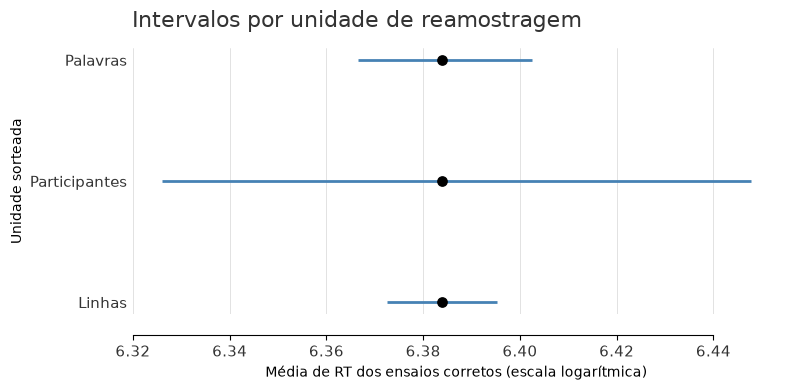

In [58]:
#| label: fig-lexdec-esquemas
#| fig-cap: "Mesma média dos ensaios e intervalos percentis nominais de 95% sob três unidades de reamostragem."
#| fig-alt: "Três segmentos horizontais para linhas, participantes e palavras. Os pontos marcam a mesma média; o intervalo por participantes é mais largo neste conjunto."
#| code-fold: true
#| code-summary: "Mostrar construção do gráfico"

y_positions = np.arange(len(resampling_intervals))
fig, ax = plt.subplots(figsize=(8, 4))

ax.hlines(
    y=y_positions,
    xmin=resampling_intervals["limite_inferior"],
    xmax=resampling_intervals["limite_superior"],
    color="steelblue",
    linewidth=2,
)
ax.scatter(
    resampling_intervals["estimativa"],
    y_positions,
    color="black",
    s=45,
    zorder=3,
)
ax.set_yticks(y_positions, labels=resampling_intervals["esquema"])
ax.set_title(
    "Intervalos por unidade de reamostragem",
    loc="left",
    fontsize=16,
    color="#333333",
    pad=15,
)
ax.set(
    xlabel="Média de RT dos ensaios corretos (escala logarítmica)",
    ylabel="Unidade sorteada",
)
ax.tick_params(axis="y", length=0)

ax.tick_params(axis="both", labelsize=11, labelcolor="#333333")
ax.grid(axis="x", alpha=0.4, linewidth=0.4, color="grey")
sns.despine(ax=ax, top=True, left=True, trim=True, offset=15)
fig.tight_layout()
plt.show()

A @fig-lexdec-esquemas mantém os pontos no mesmo valor e
altera a extensão dos segmentos. O intervalo por participantes é mais
largo neste conjunto. Escolher o mais estreito não é um critério para
escolher o esquema: a unidade precisa representar o desenho e o alcance
da inferência pretendida.

## 9. Bootstrap com SciPy

A implementação manual tornou explícitos o sorteio, a estatística e a
repetição. [`stats.bootstrap()`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.bootstrap.html)
automatiza essas etapas. Voltaremos primeiro à **média dos tempos médios
por participante**, não à média dos ensaios da seção anterior.

`data=(participant_values,)` é uma tupla de uma amostra; a vírgula final
é necessária para criar essa tupla. `statistic=np.mean` passa a função,
sem executá-la naquele ponto. `vectorized=False` pede que ela seja
aplicada a cada vetor reamostrado.

Escolhemos `method="percentile"` para reproduzir a construção manual.
O padrão da biblioteca é BCa, discutido na primeira parte; trocar o
método mudaria a regra do intervalo. `rng=rng` passa o gerador já em uso,
sem reinicializar sua sequência.

In [59]:
#| label: bootstrap-media-scipy

# O SciPy espera as amostras dentro de uma sequência.
# Como temos apenas uma amostra, usamos uma tupla com um único vetor.
mean_bootstrap_result = stats.bootstrap(
    data=(participant_values,),
    statistic=np.mean,
    n_resamples=n_bootstrap,
    confidence_level=confidence_level,
    method="percentile",
    vectorized=False,
    rng=rng,
)

As chamadas manuais e do SciPy usam trechos sucessivos da sequência
do **mesmo gerador**. Por isso, não usam as mesmas reamostragens, e não
esperamos igualdade de todos os decimais. Esperamos concordância na escala
da incerteza, sob o mesmo método e unidade.

Inspecionaremos o erro padrão, os dois limites e a quantidade de estatísticas
do objeto retornado. A forma do vetor confirma o número de reamostragens;
não informa a quantidade de participantes.

In [60]:
#| label: erro-padrao-scipy

print(
    "Erro padrão bootstrap da média (SciPy, log): "
    f"{mean_bootstrap_result.standard_error:.4f}"
)

Erro padrão bootstrap da média (SciPy, log): 0.0314


In [61]:
#| label: bootstrap-intervalo-scipy
#| classes: ["output-scroll"]

print(
    "IC percentil de 95% da média (SciPy, log): "
    f"[{mean_bootstrap_result.confidence_interval.low:.4f}; "
    f"{mean_bootstrap_result.confidence_interval.high:.4f}]"
)

IC percentil de 95% da média (SciPy, log): [6.3265; 6.4483]


In [62]:
#| label: quantidade-reamostragens-scipy

print(
    "Estatísticas bootstrap devolvidas pelo SciPy: "
    f"{mean_bootstrap_result.bootstrap_distribution.size:,} "
    f"(uma por reamostragem; n = {n_participants} participantes)."
)

Estatísticas bootstrap devolvidas pelo SciPy: 10,000 (uma por reamostragem; n = 21 participantes).


### 9.1 Resultados do SciPy e comparação manual

O objeto retornado reúne três atributos:

- `bootstrap_distribution`: uma estatística por reamostragem.
- `standard_error`: desvio-padrão amostral dessas estatísticas.
- `confidence_interval.low` e `.high`: limites do intervalo escolhido.

Repetiremos a chamada com `np.median`, usando os mesmos participantes,
$B$ e nível de confiança. A @tbl-lexdec-scipy-participantes reunirá erros
padrão e intervalos de **ambas** as implementações. Pequenas diferenças
entre as colunas decorrem dos sorteios distintos; concordância não
substitui a avaliação dos pressupostos.

In [63]:
#| label: bootstrap-mediana-scipy

# Repetimos o procedimento usando a mediana como estatística.
median_bootstrap_result = stats.bootstrap(
    data=(participant_values,),
    statistic=np.median,
    n_resamples=n_bootstrap,
    confidence_level=confidence_level,
    method="percentile",
    vectorized=False,
    rng=rng,
)

In [64]:
#| label: tbl-lexdec-scipy-participantes
#| tbl-cap: "Comparação manual e SciPy com o mesmo método percentil; RT em log."
#| classes: ["table-responsive"]

scipy_participant_summary = pd.DataFrame(
    {
        "Estatística": ["Média", "Mediana"],
        "EP manual": [
            participant_se_bootstrap,
            participant_median_se_bootstrap,
        ],
        "EP SciPy": [
            mean_bootstrap_result.standard_error,
            median_bootstrap_result.standard_error,
        ],
        "IC 95% manual": [
            f"[{bootstrap_ci_low:.4f}; {bootstrap_ci_high:.4f}]",
            f"[{bootstrap_median_ci_low:.4f}; {bootstrap_median_ci_high:.4f}]",
        ],
        "IC 95% SciPy": [
            f"[{mean_bootstrap_result.confidence_interval.low:.4f}; "
            f"{mean_bootstrap_result.confidence_interval.high:.4f}]",
            f"[{median_bootstrap_result.confidence_interval.low:.4f}; "
            f"{median_bootstrap_result.confidence_interval.high:.4f}]",
        ],
    }
)

scipy_participant_summary.round(4)

,Estatística,EP manual,EP SciPy,IC 95% manual,IC 95% SciPy
0,Média,0.0314,0.0314,[6.3252; 6.4499],[6.3265; 6.4483]
1,Mediana,0.0396,0.0403,[6.2816; 6.4218],[6.2816; 6.4218]


As duas rotas concordam na escala dos erros padrão e dos
intervalos. Na mediana, limites podem até coincidir porque o conjunto
de valores possíveis é discreto. Resultados iguais não exigem sorteios
iguais; diferenças pequenas também não indicam mudança de método.

### 9.2 Reamostragem pareada no SciPy

Na análise por palavra, cada frequência está associada ao tempo médio
do mesmo item. `paired=True` faz o SciPy sortear os **mesmos índices**
para os dois vetores, preservando essa correspondência. Isso reproduz
o sorteio de linhas completas usado na implementação manual.

Precisamos fornecer uma função que receba os dois vetores e devolva
somente o coeficiente. Ela recalcula os postos com `stats.spearmanr()`
e retorna `statistic`, deixando de fora o outro resultado da função.
O SciPy aplicará essa função a cada reamostragem.

Preservar os pares é diferente de representar participantes e palavras
cruzados. `paired=True` protege a associação entre os dois valores de
cada item; não incorpora a incerteza dos participantes.

In [65]:
#| label: tbl-lexdec-scipy-spearman
#| tbl-cap: "Spearman: bootstrap manual de pares e SciPy com paired=True."
#| classes: ["table-responsive"]


def spearman_statistic(frequency: np.ndarray, mean_rt: np.ndarray) -> float:
    """Retorna apenas o coeficiente da correlação de Spearman."""
    return float(stats.spearmanr(frequency, mean_rt).statistic)


# O SciPy reamostra os mesmos índices dos dois vetores.
spearman_bootstrap_result = stats.bootstrap(
    data=(
        word_df["frequency_log"].to_numpy(),
        word_df["mean_rt"].to_numpy(),
    ),
    statistic=spearman_statistic,
    paired=True,  # preserva os pares frequência–tempo
    n_resamples=n_bootstrap,
    confidence_level=confidence_level,
    method="percentile",
    vectorized=False,
    rng=rng,
)


pd.DataFrame(
    {
        "Implementação": ["Manual", "SciPy pareado"],
        "Spearman observado": [observed_rho, observed_rho],
        "EP bootstrap": [
            spearman_se_bootstrap,
            spearman_bootstrap_result.standard_error,
        ],
        "IC 95% inferior": [
            spearman_ci_low,
            spearman_bootstrap_result.confidence_interval.low,
        ],
        "IC 95% superior": [
            spearman_ci_high,
            spearman_bootstrap_result.confidence_interval.high,
        ],
    }
).round(4)

,Implementação,Spearman observado,EP bootstrap,IC 95% inferior,IC 95% superior
0,Manual,-0.7276,0.0611,-0.8283,-0.5898
1,SciPy pareado,-0.7276,0.0612,-0.8285,-0.5897


O bootstrap pareado do SciPy recupera uma incerteza próxima
da implementação manual: ambas mantêm frequência e RT do mesmo item juntos.
O intervalo negativo retoma o padrão observado entre as palavras.
A automação altera a implementação, mantendo o alvo e o alcance da análise.

## 10. Síntese

Partimos de ensaios de decisão lexical e construímos tabelas adequadas
a três estatísticas: média e mediana dos tempos médios por participante,
e Spearman entre frequência e tempo médio por palavra.

Antes do bootstrap, definimos:

1. **Alvo:** a quantidade que queremos estimar.
2. **Estatística:** a função dos dados que representa esse alvo.
3. **Unidade:** o que será sorteado com reposição.
4. **Dependência:** quais valores precisam permanecer juntos.
5. **Alcance:** qual população ou processo o procedimento pode representar.

O mecanismo foi o mesmo: reamostrar, recalcular a estatística, repetir
e estudar a distribuição. A @tbl-lexdec-resultados reúne os resultados
do SciPy com intervalos percentis nominais de 95%.

In [66]:
#| label: tbl-lexdec-resultados
#| tbl-cap: "Resultados SciPy: RT em log para média e mediana; Spearman adimensional."
#| classes: ["table-responsive"]

# Reunimos os resultados principais das três análises.
final_results = pd.DataFrame(
    {
        "estatistica": [
            "Média dos tempos médios",
            "Mediana dos tempos médios",
            "Spearman: frequência × RT",
        ],
        "unidade_reamostrada": [
            "Participante",
            "Participante",
            "Palavra",
        ],
        "n": [
            n_participants,
            n_participants,
            n_words,
        ],
        "estimativa": [
            participant_mean,
            participant_median,
            observed_rho,
        ],
        "erro_padrao_bootstrap": [
            mean_bootstrap_result.standard_error,
            median_bootstrap_result.standard_error,
            spearman_bootstrap_result.standard_error,
        ],
        "ic_95_inferior": [
            mean_bootstrap_result.confidence_interval.low,
            median_bootstrap_result.confidence_interval.low,
            spearman_bootstrap_result.confidence_interval.low,
        ],
        "ic_95_superior": [
            mean_bootstrap_result.confidence_interval.high,
            median_bootstrap_result.confidence_interval.high,
            spearman_bootstrap_result.confidence_interval.high,
        ],
    }
)

final_results["IC 95%"] = [
    f"[{low:.4f}; {high:.4f}]"
    for low, high in zip(
        final_results["ic_95_inferior"], final_results["ic_95_superior"]
    )
]

final_results.rename(
    columns={
        "estatistica": "Estatística",
        "unidade_reamostrada": "Unidade",
        "estimativa": "Estimativa",
        "erro_padrao_bootstrap": "EP bootstrap",
    },
).set_index("Estatística")[
    ["Unidade", "n", "Estimativa", "EP bootstrap", "IC 95%"]
].round(4)

,Unidade,n,Estimativa,EP bootstrap,IC 95%
Estatística,,,,,
Média dos tempos médios,Participante,21,6.3845,0.0314,[6.3265; 6.4483]
Mediana dos tempos médios,Participante,21,6.3759,0.0403,[6.2816; 6.4218]
Spearman: frequência × RT,Palavra,79,-0.7276,0.0612,[-0.8285; -0.5897]


### 10.1 Estimativa, incerteza e desenho

A média dos tempos médios é cerca de 6,3845 e sua mediana, 6,3759,
na escala logarítmica. Os procedimentos mantêm peso igual por pessoa,
mas resumem aspectos distintos da posição dos 21 valores. A mediana
apresenta maior erro padrão bootstrap nesta amostra; menor sensibilidade
a valores afastados não implica menor incerteza.

Entre as 79 palavras, Spearman fica perto de $-0{,}728$, e o intervalo
permanece no lado negativo sob o bootstrap de itens. Isso sustenta a
descrição de uma associação negativa neste esquema, sem demonstrar
causalidade ou generalização simultânea para novos participantes.

O **desvio-padrão** descreve a dispersão entre unidades; o **erro padrão**,
a variação de uma estatística sob amostras repetidas. O erro padrão bootstrap
aproxima essa variação por reamostragem. $n$ conta unidades observadas;
$B$ conta repetições no computador.

Aumentar $B$ melhora a aproximação computacional sem aumentar a
informação presente nos dados. Comparar ensaios, participantes e palavras
mostrou que a **unidade de reamostragem faz parte da análise**. O bootstrap
automatiza a repetição; a pergunta e o desenho determinam o que deve
ser repetido e como interpretar o resultado.

**Referências de consulta:** [LexDec no manual de `languageR`](https://cran.r-project.org/web/packages/languageR/languageR.pdf#page=54),
[geradores do NumPy](https://numpy.org/doc/stable/reference/random/generator.html),
[`DataFrame.sample()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.sample.html)
e [`stats.bootstrap()`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.bootstrap.html).